# 03 - Exploratory Data Analysis (EDA)

In this notebook I look at the clean data to understand the patterns in electricity demand.
Each finding is used to decide which features to build in notebook 04.

### 1. Import libraries and load the clean data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import holidays

figures_folder = "../results/figures"

data = pd.read_csv("../datasets/processed/gb_clean_2015_2019.csv")
data["time"] = pd.to_datetime(data["time"], utc=True)

# UK local time is used for hours, days and months, because people follow the clock
uk_time = data["time"].dt.tz_convert("Europe/London")
data["year"] = uk_time.dt.year
data["month"] = uk_time.dt.month
data["hour"] = uk_time.dt.hour
data["day_of_week"] = uk_time.dt.dayofweek

print("Rows:", len(data))

Rows: 43824


In [2]:
data[["load", "temperature"]].describe()

,load,temperature
count,43824.000000,43824.000000
mean,35567.486229,9.865687
std,7681.039215,5.508153
min,14356.000000,-4.516000
25%,29603.750000,5.681000
50%,36170.000000,9.492500
75%,41164.000000,13.873000
max,57388.000000,29.105000


### 2. Load over the whole period

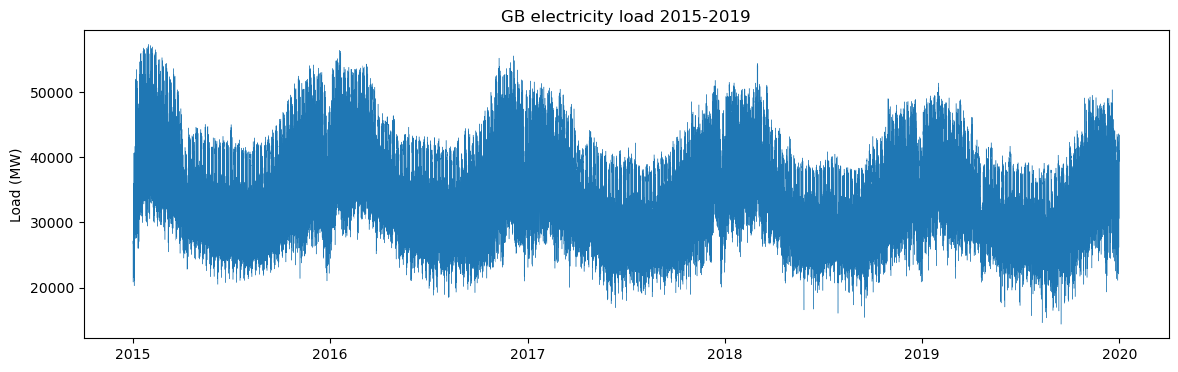

In [3]:
plt.figure(figsize=(14, 4))
plt.plot(data["time"], data["load"], linewidth=0.3)
plt.title("GB electricity load 2015-2019")
plt.ylabel("Load (MW)")
plt.savefig(figures_folder + "/03_load_all.png")
plt.show()

year
2015    37276.0
2016    37160.0
2017    34410.0
2018    34817.0
2019    34170.0
Name: load, dtype: float64


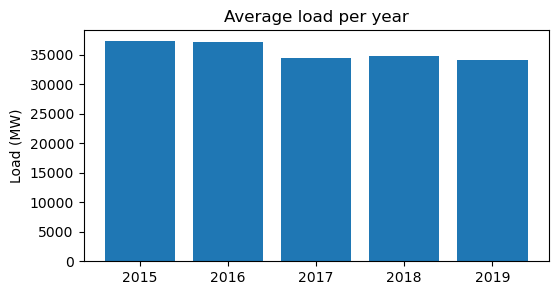

In [4]:
yearly = data.groupby("year")["load"].mean()
print(yearly.round(0))

plt.figure(figsize=(6, 3))
plt.bar(yearly.index, yearly.values)
plt.title("Average load per year")
plt.ylabel("Load (MW)")
plt.show()

Average demand is lower in 2017-2019 than in 2015-2016 (more energy efficiency and more rooftop solar). The models must handle this slow change in level.

### 3. Distribution of load

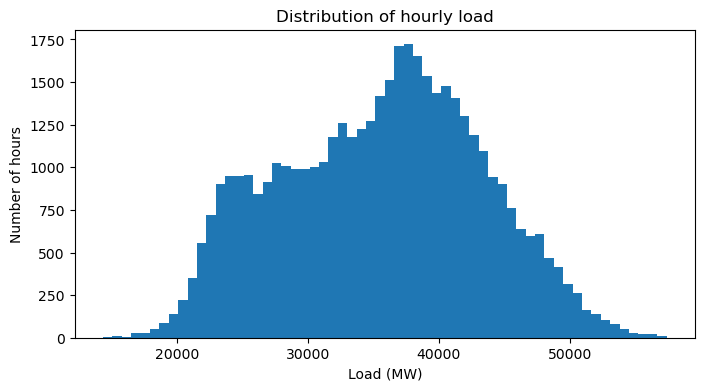

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(data["load"], bins=60)
plt.title("Distribution of hourly load")
plt.xlabel("Load (MW)")
plt.ylabel("Number of hours")
plt.savefig(figures_folder + "/03_distribution.png")
plt.show()

### 4. Yearly pattern (month)

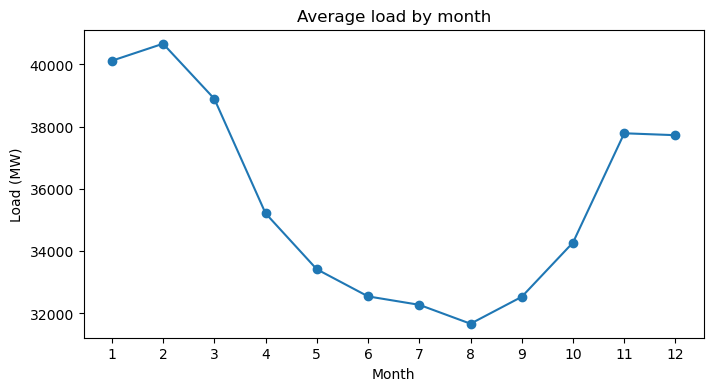

In [6]:
monthly = data.groupby("month")["load"].mean()

plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Average load by month")
plt.xlabel("Month")
plt.ylabel("Load (MW)")
plt.xticks(range(1, 13))
plt.savefig(figures_folder + "/03_by_month.png")
plt.show()

Demand is highest in winter and lowest in summer. **This is why `month` is a feature.**

### 5. Daily pattern (hour)

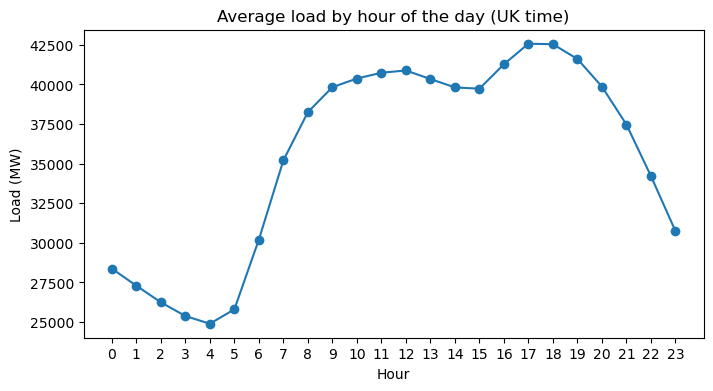

Lowest hour : 4
Highest hour: 17


In [7]:
hourly = data.groupby("hour")["load"].mean()

plt.figure(figsize=(8, 4))
plt.plot(hourly.index, hourly.values, marker="o")
plt.title("Average load by hour of the day (UK time)")
plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.xticks(range(0, 24))
plt.savefig(figures_folder + "/03_by_hour.png")
plt.show()

print("Lowest hour :", hourly.idxmin())
print("Highest hour:", hourly.idxmax())

Demand is lowest at night (around 4 am) and highest in the early evening (around 5-6 pm). **This is why `hour` and `lag_24` are features.**

### 6. Weekly pattern (day of week)

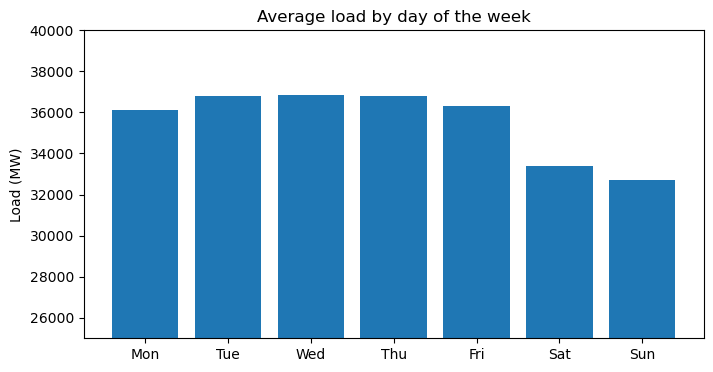

In [8]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
daily = data.groupby("day_of_week")["load"].mean()

plt.figure(figsize=(8, 4))
plt.bar(day_names, daily.values)
plt.title("Average load by day of the week")
plt.ylabel("Load (MW)")
plt.ylim(25000, 40000)
plt.savefig(figures_folder + "/03_by_day.png")
plt.show()

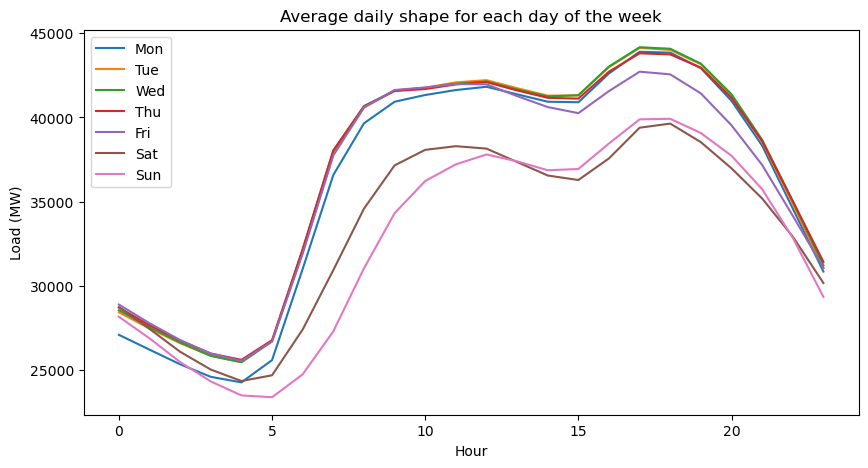

In [9]:
# daily shape for each day of the week
plt.figure(figsize=(10, 5))
for day in range(7):
    one_day = data[data["day_of_week"] == day].groupby("hour")["load"].mean()
    plt.plot(one_day.index, one_day.values, label=day_names[day])
plt.title("Average daily shape for each day of the week")
plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/03_daily_shape_by_day.png")
plt.show()

Monday to Friday look almost the same. Saturday and Sunday are lower, especially in the morning. **This is why `day_of_week`, `is_weekend` and `lag_168` are features.**

### 7. Holidays

Weekday : 36727
Weekend : 33052 ( -10 % )
Holiday : 31846 ( -13 % )


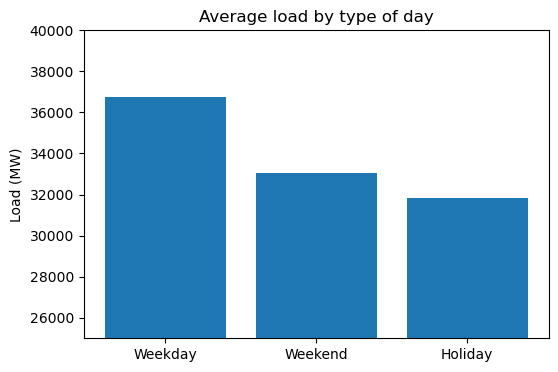

In [10]:
uk_holidays = holidays.UK(subdiv="ENG", years=[2015, 2016, 2017, 2018, 2019])
data["is_holiday"] = uk_time.dt.date.isin(list(uk_holidays.keys())).astype(int)
data["is_weekend"] = (data["day_of_week"] >= 5).astype(int)

weekday = data[(data["is_weekend"] == 0) & (data["is_holiday"] == 0)]["load"].mean()
weekend = data[(data["is_weekend"] == 1) & (data["is_holiday"] == 0)]["load"].mean()
holiday = data[data["is_holiday"] == 1]["load"].mean()

print("Weekday :", round(weekday))
print("Weekend :", round(weekend), "(", round((weekend / weekday - 1) * 100), "% )")
print("Holiday :", round(holiday), "(", round((holiday / weekday - 1) * 100), "% )")

plt.figure(figsize=(6, 4))
plt.bar(["Weekday", "Weekend", "Holiday"], [weekday, weekend, holiday])
plt.title("Average load by type of day")
plt.ylabel("Load (MW)")
plt.ylim(25000, 40000)
plt.savefig(figures_folder + "/03_day_type.png")
plt.show()

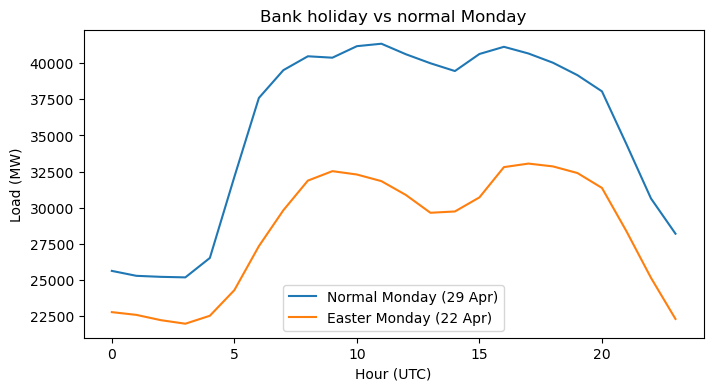

In [11]:
# example: Easter Monday 2019 compared with a normal Monday
easter_monday = data[(data["time"] >= "2019-04-22") & (data["time"] < "2019-04-23")]
normal_monday = data[(data["time"] >= "2019-04-29") & (data["time"] < "2019-04-30")]

plt.figure(figsize=(8, 4))
plt.plot(range(24), normal_monday["load"].values, label="Normal Monday (29 Apr)")
plt.plot(range(24), easter_monday["load"].values, label="Easter Monday (22 Apr)")
plt.title("Bank holiday vs normal Monday")
plt.xlabel("Hour (UTC)")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/03_easter_monday.png")
plt.show()

A bank holiday looks like a Sunday, even if it is a Monday. **This is why `is_holiday` is a feature.**

### 8. Temperature

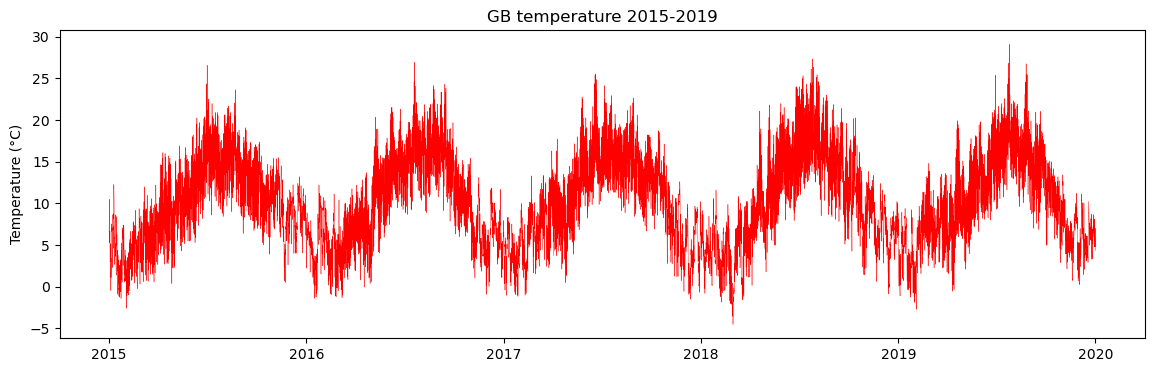

In [12]:
plt.figure(figsize=(14, 4))
plt.plot(data["time"], data["temperature"], linewidth=0.3, color="red")
plt.title("GB temperature 2015-2019")
plt.ylabel("Temperature (°C)")
plt.show()

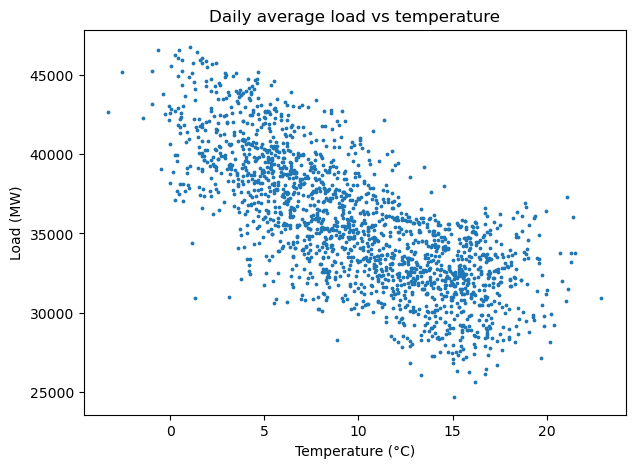

Correlation (daily): -0.74
Correlation (hourly): -0.13


In [13]:
# daily averages, because the hourly pattern hides the temperature effect
daily_data = data.set_index("time")[["load", "temperature"]].resample("D").mean()

plt.figure(figsize=(7, 5))
plt.scatter(daily_data["temperature"], daily_data["load"], s=3)
plt.title("Daily average load vs temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Load (MW)")
plt.savefig(figures_folder + "/03_load_vs_temperature.png")
plt.show()

print("Correlation (daily):", round(daily_data["load"].corr(daily_data["temperature"]), 2))
print("Correlation (hourly):", round(data["load"].corr(data["temperature"]), 2))

Colder days have higher demand (daily correlation about -0.73). The hourly correlation is weak because the daily pattern is much stronger than the temperature effect.
The line flattens above about 15 °C because the UK uses very little air conditioning. **This is why `temperature` is a feature.**

### 9. Autocorrelation: how much does load depend on the past?

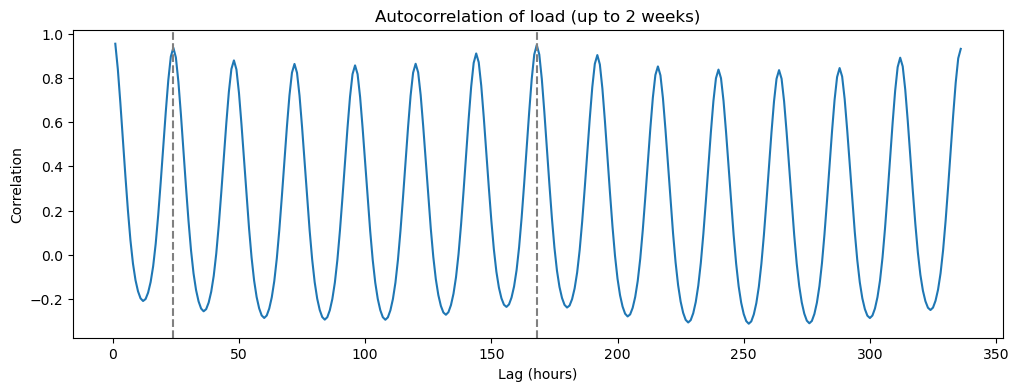

Lag 1  : 0.954
Lag 24 : 0.936
Lag 168: 0.948


In [14]:
# correlation between load now and load k hours before
lags = range(1, 337)  # up to 2 weeks
autocorr = []
for k in lags:
    autocorr.append(data["load"].autocorr(lag=k))

plt.figure(figsize=(12, 4))
plt.plot(lags, autocorr)
plt.axvline(24, color="grey", linestyle="--")
plt.axvline(168, color="grey", linestyle="--")
plt.title("Autocorrelation of load (up to 2 weeks)")
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")
plt.savefig(figures_folder + "/03_autocorrelation.png")
plt.show()

print("Lag 1  :", round(data["load"].autocorr(lag=1), 3))
print("Lag 24 :", round(data["load"].autocorr(lag=24), 3))
print("Lag 168:", round(data["load"].autocorr(lag=168), 3))

There are peaks every 24 hours (same hour yesterday) and a higher peak at 168 hours (same hour last week). **This is why `lag_1`, `lag_24` and `lag_168` are features.**

### 10. Summary: what the EDA shows and which feature it leads to

| Finding | Feature |
|---|---|
| Load depends strongly on the hour before | `lag_1` |
| Strong daily pattern (peak at 24 hours in autocorrelation) | `lag_24`, `hour`, `rolling_mean_24` |
| Strong weekly pattern (peak at 168 hours) | `lag_168`, `day_of_week`, `rolling_mean_168` |
| Weekends are lower than weekdays | `is_weekend` |
| Bank holidays behave like Sundays | `is_holiday` |
| Winter is higher than summer | `month` |
| Cold days have higher demand | `temperature` |
| Slow fall in demand every year | `rolling_mean_168` follows the level |

**Next:** notebook 04 - build these features and split the data.